# Tabular — Klasifikasi
**Kapan dipakai:** data berbentuk tabel (CSV), dan kita diminta menebak kategori (label)
untuk tiap baris test. Contoh: selamat/tidak, churn/tidak, kelas A/B/C.

**Langkah:**
1. Baca data, lihat isinya.
2. Bagi train menjadi train dan validasi untuk mengukur model.
3. Siapkan kolom (isi yang kosong, samakan skala, ubah kategori jadi angka), lalu latih model.
4. Latih ulang di semua data train, tebak test, simpan submission.

**Data demo:** Titanic (target `survived`). Ganti path dan nama kolom di sel Konfigurasi.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

## Konfigurasi
Semua yang boleh diubah ada di sel ini.

In [2]:
DATA_FOLDER = "../../data_latihan/tabular/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/titanic_train.csv"
TEST_CSV = f"{DATA_FOLDER}/titanic_test.csv"

TARGET = "survived"                                    # kolom yang ditebak
NUM_COLS = ["pclass", "age", "sibsp", "parch", "fare"]   # kolom angka
CAT_COLS = ["sex", "embarked", "who", "deck"]            # kolom kategori (teks)
SEED = 42

## Baca data
`isna().sum()` = jumlah sel kosong per kolom.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train.isna().sum())
train.head()

train: (712, 16) | test: (179, 15)
id               0
survived         0
pclass           0
sex              0
age            137
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           553
embark_town      2
alive            0
alone            0
dtype: int64


,id,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,693,1,3,male,NaN,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True
1,482,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True
2,528,0,1,male,NaN,0,0,221.7792,S,First,man,True,C,Southampton,no,True
3,856,1,3,female,18.0,0,1,9.3500,S,Third,woman,False,NaN,Southampton,yes,False
4,802,1,2,female,31.0,1,1,26.2500,S,Second,woman,False,NaN,Southampton,yes,False


## EDA
- Proporsi tiap label: kalau sangat timpang, pakai F1 macro, jangan akurasi.
- Histogram kolom angka.
- Rata-rata target per kategori: kategori mana yang paling berpengaruh.

survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64


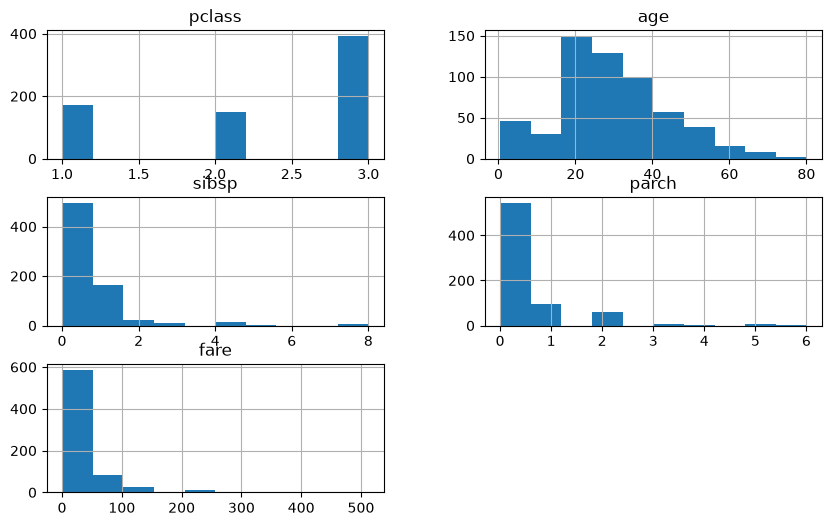

            mean  count
sex                    
female  0.743083    253
male    0.185185    459 

              mean  count
embarked                 
C         0.561151    139
Q         0.436364     55
S         0.327519    516 

           mean  count
who                   
child  0.590909     66
man    0.161215    428
woman  0.756881    218 

          mean  count
deck                 
A     0.428571     14
B     0.735294     34
C     0.682927     41
D     0.807692     26
E     0.758621     29
F     0.727273     11
G     0.500000      4 



In [4]:
print(train[TARGET].value_counts(normalize=True))
train[NUM_COLS].hist(figsize=(10, 6))
plt.show()

for col in CAT_COLS:
    print(train.groupby(col)[TARGET].agg(["mean", "count"]), "\n")

## Split train / validasi
20% data train disisihkan untuk mengukur model. `stratify=y` menjaga proporsi label sama.

In [5]:
X = train[NUM_COLS + CAT_COLS]
y = train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("train:", X_train.shape, "| validasi:", X_val.shape)

train: (569, 9) | validasi: (143, 9)


## Model
`preprocess` menyiapkan kolom:
- kolom angka: isi yang kosong dengan median, lalu samakan skala (StandardScaler);
- kolom kategori: isi yang kosong dengan nilai terbanyak, lalu ubah jadi kolom 0/1 (OneHot).

Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
num_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore"))
preprocess = ColumnTransformer([
    ("num", num_steps, NUM_COLS),
    ("cat", cat_steps, CAT_COLS),
])

model = LogisticRegression(C=1.0, max_iter=2000)                      # cepat, mudah dijelaskan
# model = RandomForestClassifier(n_estimators=500, random_state=SEED)
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED)
# model = HistGradientBoostingClassifier(random_state=SEED)
# model = LGBMClassifier(n_estimators=500, learning_rate=0.03, random_state=SEED, verbose=-1)
# model = XGBClassifier(n_estimators=500, learning_rate=0.03, random_state=SEED)
# model = CatBoostClassifier(iterations=500, random_seed=SEED, verbose=0)
# model = SVC(C=1.0, random_state=SEED)
# model = KNeighborsClassifier(n_neighbors=15)
# model = DecisionTreeClassifier(max_depth=6, random_state=SEED)
# model = GradientBoostingClassifier(random_state=SEED)
# model = AdaBoostClassifier(n_estimators=300, random_state=SEED)
# model = BaggingClassifier(n_estimators=100, random_state=SEED)
# model = RidgeClassifier(alpha=1.0)
# model = MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=SEED)

pipe = make_pipeline(preprocess, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['pclass','age','sibsp',...,'embarked','who','deck']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rem

## Evaluasi di validasi
F1 macro = rata-rata F1 semua label (label kecil dihitung sama penting).
Confusion matrix: baris = label asli, kolom = tebakan.

F1 macro: 0.8012


              precision    recall  f1-score   support

           0       0.85      0.84      0.85        88
           1       0.75      0.76      0.76        55

    accuracy                           0.81       143
   macro avg       0.80      0.80      0.80       143
weighted avg       0.81      0.81      0.81       143



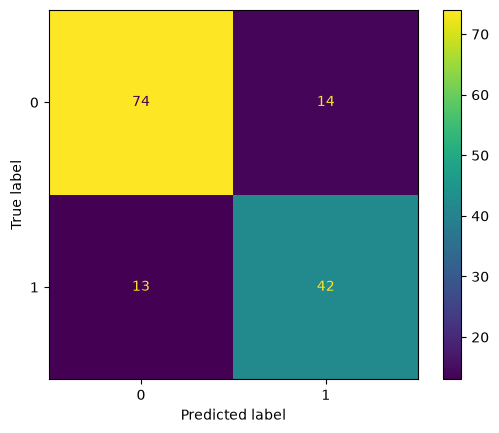

In [7]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions)
plt.show()

## Latih ulang di semua data + submission
Nama kolom submission disalin dari format soal.

In [8]:
pipe.fit(X, y)
predictions = pipe.predict(test[NUM_COLS + CAT_COLS])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["survived"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,survived
0,566,0
1,161,0
2,554,0
3,861,0
4,242,1
